# Arginyl peptides: functional evidence and charge-matched controls

**Ratchanon Preecha · 15 October 2026**

**Question:** does the existing evidence distinguish an arginine-specific effect from a property shared by positively charged peptides, and which comparison should follow?

This notebook **recalculates the reviewed evidence and chemical comparisons**: 32 published human taste-cell conditions, separate knockdown controls, a source-limited soy comparison, and explicit AR/AK, RA/KA and RP/KP chemical pairs. The underlying biological effects belong to the original authors. AK, KA and KP remain unmeasured controls in this project.

**Runtime: CPU. A GPU is not required.** There is no neural-network training, docking, molecular dynamics or simulated cell experiment. Analysis takes seconds; a fresh environment needs package downloads. No API key, file upload or paid service is required. Internet is used for environment setup only.

**Run all, then read the outputs in order.** All inputs and readable analysis code are embedded and hash-checked. New run outputs are kept separate from embedded reference tables. The last cell exports source, inputs, results and logs. Local execution is recorded in this copy; Colab browser execution is not claimed.

[Project](https://github.com/preecharatchanon-arch/Ratc/tree/main/projects/salt-casr) · [Focused research note](https://github.com/preecharatchanon-arch/Ratc/blob/main/projects/salt-casr/docs/ARGINYL_STARTING_POINT.md)


In [1]:
from pathlib import Path
import os
os.environ['MPLBACKEND'] = 'Agg'  # Before any plotting import or worker launch.
import sys,subprocess,shutil,hashlib,json,base64,io,zipfile,csv,html,time,math
from IPython.display import display,HTML,Image,FileLink
NOTEBOOK_STARTED=time.monotonic()
BASE=Path('/content/salt_functional_controls') if Path('/content').is_dir() else Path.cwd()/'salt_functional_controls'
PROJECT=BASE/'work/salt-casr'
EXP=PROJECT/'experiments/05-functional-assay-controls'
LOGS=BASE/'logs'
PROJECT.mkdir(parents=True,exist_ok=True);LOGS.mkdir(parents=True,exist_ok=True)
PAYLOAD_SHA256='a72dbc8763f1cd0aa0575a912eefbc369f8f96ac2834bd8fbc4bd45878ab916a'
EMBEDDED_INPUTS='...'
payload=base64.b64decode(EMBEDDED_INPUTS)
if hashlib.sha256(payload).hexdigest()!=PAYLOAD_SHA256:raise ValueError('Embedded package checksum mismatch')
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    if archive.testzip() is not None:raise ValueError('Embedded ZIP corruption')
    for name in archive.namelist():
        target=(PROJECT/name).resolve()
        if not target.is_relative_to(PROJECT.resolve()):raise ValueError('Unexpected embedded path')
        target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(archive.read(name))
EMBEDDED_MANIFEST=json.loads((PROJECT/'EMBEDDED_MANIFEST.json').read_text())
for name,record in EMBEDDED_MANIFEST.items():
    data=(PROJECT/name).read_bytes()
    if len(data)!=record['bytes'] or hashlib.sha256(data).hexdigest()!=record['sha256']:raise ValueError('Input mismatch: '+name)
print('Verified embedded files:',len(EMBEDDED_MANIFEST))
print('Package SHA-256:',PAYLOAD_SHA256)
print('Working folder:',PROJECT)


Verified embedded files: 29
Package SHA-256: a72dbc8763f1cd0aa0575a912eefbc369f8f96ac2834bd8fbc4bd45878ab916a
Working folder: /workspace/scratch/cadb742a5030/research/arginyl_notebook_20261015/notebook_validation_no_uv/salt_functional_controls/work/salt-casr


## 1. Prepare the CPU environment

The notebook kernel orchestrates a separate **Python 3.12 worker** with pinned binary packages. This avoids changing Colab's scientific stack. `MPLBACKEND=Agg` is applied to every worker, addressing the earlier inherited inline-backend error. No Vina or compiler is needed.

The setup verifies Python, all pinned versions and dependency consistency. It can be rerun in the same runtime; analysis cells recompute their outputs.


In [2]:
def command(args,name,timeout=900):
    env=os.environ.copy()
    env.update(MPLBACKEND='Agg',OMP_NUM_THREADS='2',OPENBLAS_NUM_THREADS='2',MKL_NUM_THREADS='2')
    path=LOGS/(name+'.log');started=time.monotonic()
    print('Running:',name,flush=True)
    try:
        with path.open('w') as out:
            result=subprocess.run([str(a) for a in args],cwd=EXP,env=env,stdout=out,stderr=subprocess.STDOUT,timeout=timeout)
    except subprocess.TimeoutExpired as exc:
        print(path.read_text(errors='replace')[-5000:]);raise RuntimeError('Timed out: '+name+'; log: '+str(path)) from exc
    if result.returncode:
        print(path.read_text(errors='replace')[-5000:]);raise RuntimeError('Failed: '+name+'; log: '+str(path))
    print(name+':',round(time.monotonic()-started,2),'s',flush=True)
    return time.monotonic()-started

uv=shutil.which('uv')
if uv is None or subprocess.check_output([uv,'--version'],text=True).split()[1]!='0.12.23':
    bootstrap=BASE/'bootstrap'
    command([sys.executable,'-m','pip','install','--quiet','--upgrade','--only-binary=:all:','--target',bootstrap,'uv==0.12.23'],'bootstrap_uv')
    uv=str(bootstrap/'bin/uv')
PY=BASE/'python312/bin/python'
if not PY.exists():command([uv,'venv','--python','3.12',PY.parent.parent],'create_python312')
command([uv,'pip','install','--python',PY,'--only-binary',':all:','-r',EXP/'requirements_notebook.txt'],'install_locked_packages')
command([uv,'pip','check','--python',PY],'check_dependencies')
expected=dict(line.split('==') for line in (EXP/'requirements_notebook.txt').read_text().splitlines() if '==' in line and not line.startswith('#'))
query='import sys,json,importlib.metadata as m;print(json.dumps({"python":list(sys.version_info[:3]),"packages":{n:m.version(n) for n in '+repr(list(expected))+'}}))'
actual=json.loads(subprocess.check_output([str(PY),'-c',query],text=True))
if actual['python'][:2]!=[3,12] or actual['packages']!=expected:raise RuntimeError('Worker version mismatch')
(PROJECT/'worker_environment.json').write_text(json.dumps(actual,indent=2)+'\n')
print('Verified Python',actual['python'],'and',len(expected),'pinned packages. CPU only.')


Running: bootstrap_uv
bootstrap_uv: 23.82 s
Running: create_python312
create_python312: 0.07 s
Running: install_locked_packages
install_locked_packages: 0.12 s
Running: check_dependencies
check_dependencies: 0.02 s
Verified Python [3, 12, 3] and 12 pinned packages. CPU only.


## 2. Recalculate the published functional evidence

The 32 records are **tested peptide-dose/NaCl conditions**, not 32 independent molecules. The response is a fraction of cultured human taste cells with a calcium response. The original authors compare the mixture with **SUM**, their arithmetic sum of peptide-only and NaCl-only response fractions.

The analysis keeps the two knockdown cohorts separate, preserves reported non-significance rather than replacing it with zero, and does not reconstruct p-values from pooled cells. Its figure also shows the soy endpoint comparison; that component is limited to the accessible publisher abstract and has unverified organoid conditions.


Running: functional_evidence
functional_evidence: 2.42 s
condition_summary.csv: 7 rows
separate_SUM_contrasts.csv: 3 rows
At 100 µM: {'tested_records': 14, 'reported_increases': 0}
This does not establish a significant between-dose difference or an absence of all effects.


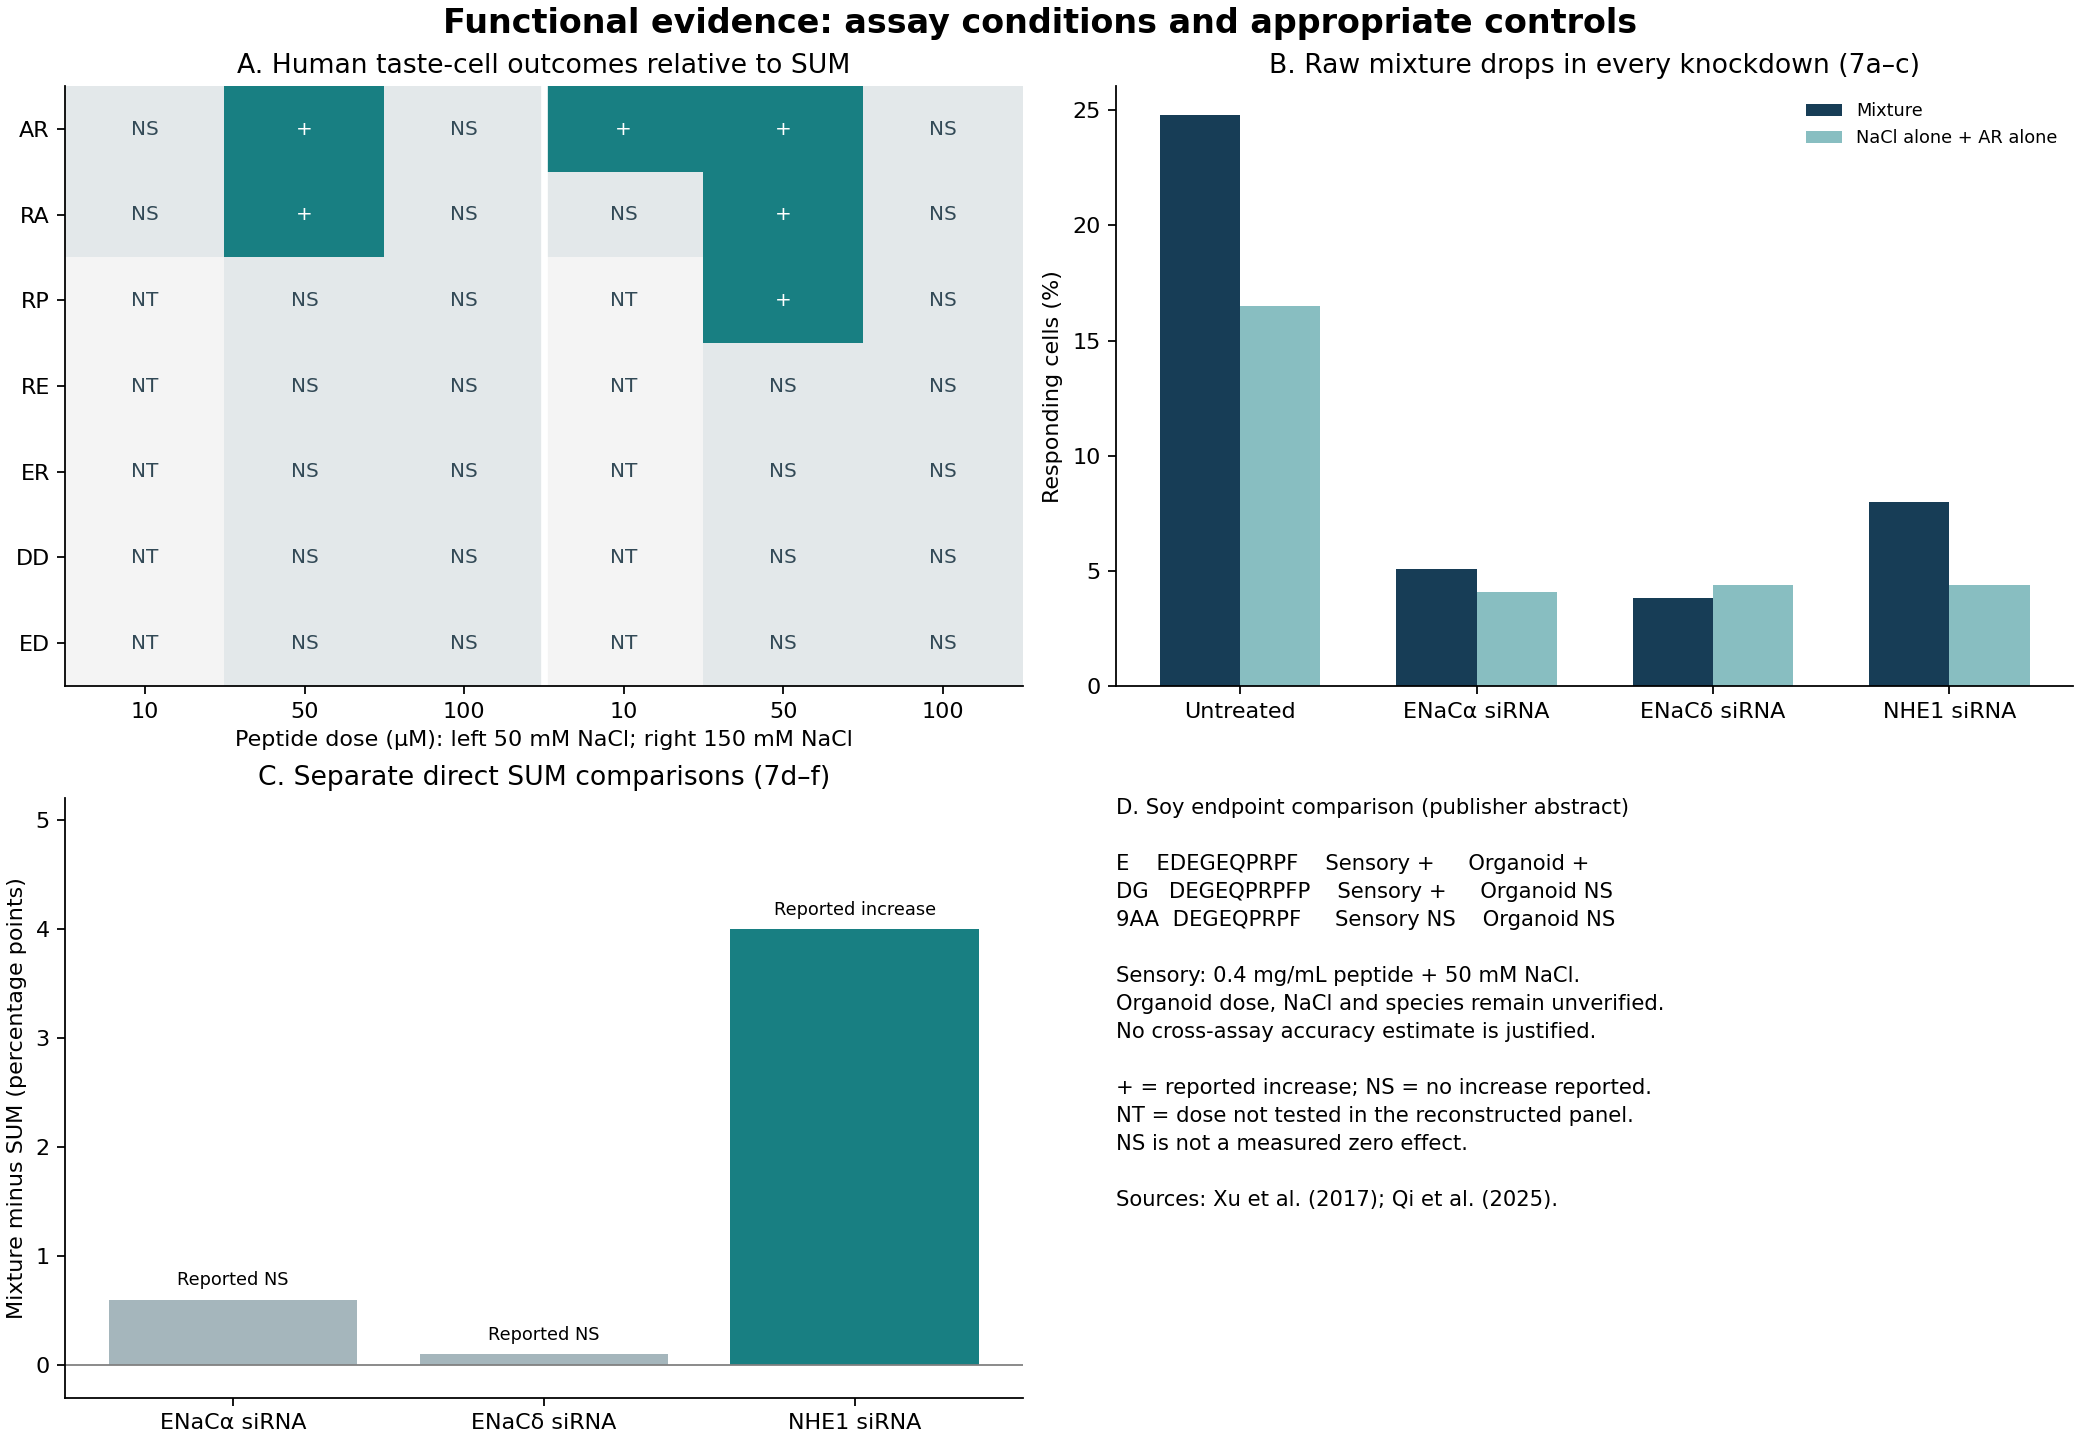

sequence,tested_conditions,reported_increases,other_tested_conditions
AR,6,3,3
RA,6,2,4
RP,4,1,3
RE,4,0,4
ER,4,0,4
DD,4,0,4
ED,4,0,4


treatment,SUM_pct,mixture_pct,excess_over_SUM_pp,reported_outcome
ENaC_alpha_siRNA,3.8,4.4,0.6,no_significant_increase_reported
ENaC_delta_siRNA,4.4,4.5,0.1,no_significant_increase_reported
NHE1_siRNA,5.1,9.1,4,significant_increase_reported


In [3]:
command([PY,EXP/'code/analyse_functional.py'],'functional_evidence')
RESULTS=EXP/'runs/latest'
CONTROL=EXP/'runs/control_selection'
def table(path,columns=None,limit=None):
    path=Path(path)
    with path.open(newline='') as f:
        reader=csv.DictReader(f);rows=list(reader);fields=columns or reader.fieldnames
    shown=rows if limit is None else rows[:limit]
    def esc(value):
        text=str(value)
        try:
            number=float(text)
            if math.isfinite(number) and '.' in text:text=format(number,'.6g')
        except (ValueError,TypeError):pass
        return html.escape(text)
    head='<tr>'+''.join('<th>'+esc(x)+'</th>' for x in fields)+'</tr>'
    body=''.join('<tr>'+''.join('<td>'+esc(row.get(x,''))+'</td>' for x in fields)+'</tr>' for row in shown)
    display(HTML('<style>.research-table{border-collapse:collapse;font-size:13px}.research-table th{background:#173d56;color:white}.research-table td,.research-table th{padding:7px;border:1px solid #ccd5dc;text-align:left}.research-table tr:nth-child(even){background:#f1f6f7}</style><div style="overflow:auto"><table class="research-table">'+head+body+'</table></div>'))
    print(path.name+':',len(rows),'rows'+(' (first '+str(limit)+' shown)' if limit is not None and len(rows)>limit else ''))

display(Image(filename=str(RESULTS/'functional_controls.png')))
table(RESULTS/'condition_summary.csv',['sequence','tested_conditions','reported_increases','other_tested_conditions'])
table(RESULTS/'separate_SUM_contrasts.csv',['treatment','SUM_pct','mixture_pct','excess_over_SUM_pp','reported_outcome'])
functional_summary=json.loads((RESULTS/'analysis_summary.json').read_text())
print('At 100 µM:',functional_summary['at_100_uM'])
print('This does not establish a significant between-dose difference or an absence of all effects.')


## 3. Inspect charge-matched chemical controls

At **50 μM peptide / reported 150 mM NaCl**, AR, RA and RP are the three nominally positive-side-chain comparators and the three with reported enhancement in the selected panel. No lysine-containing dipeptide was tested in that panel. The association does not explain every dose/NaCl condition.

The proposed **AR/AK, RA/KA and RP/KP** comparisons retain two residues and nominal side-chain balance +1 while replacing guanidinium-bearing Arg with amine-bearing Lys. This changes several chemical properties, so it is not a perfect isolation of charge. **No activity is predicted for AK, KA or KP.**

Nominal balance means `(number of Arg + Lys) − (number of Asp + Glu)` at approximately neutral pH. It is not measured net charge, a pKa model or the formal charge of the neutral connectivity graph. RDKit encodes ordinary α-linked L-dipeptides here; it must not be used to substitute an ordinary EVG sequence for γ-Glu-Val-Gly.


Running: chemical_control_selection
chemical_control_selection: 0.26 s
condition_charge_strata.csv: 4 rows
matched_control_pairs.csv: 3 rows
control_panel_chemistry.csv: 12 rows
Running: draw_control_structures
draw_control_structures: 0.37 s


peptide_uM,reported_NaCl_stimulus_mM,positive_balance_tested,positive_balance_with_reported_increase,nonpositive_balance_tested,nonpositive_balance_with_reported_increase
50,50,3,2,4,0
50,150,3,3,4,0
100,50,3,0,4,0
100,150,3,0,4,0


reference,proposed_control,reference_sidechain_balance,control_sidechain_balance,control_HBO_result
AR,AK,1,1,unverified_in_sources_reviewed
RA,KA,1,1,unverified_in_sources_reviewed
RP,KP,1,1,unverified_in_sources_reviewed


sequence,role,formula,free_form_average_MW_g_mol,nominal_sidechain_balance,calculated_free_form_mg_L_at_50_uM
AR,published_HBO_comparator,C9H19N5O3,245.283,1,12.2642
RA,published_HBO_comparator,C9H19N5O3,245.283,1,12.2642
RP,published_HBO_comparator,C11H21N5O3,271.321,1,13.566
RE,published_HBO_comparator,C11H21N5O5,303.319,0,15.166
ER,published_HBO_comparator,C11H21N5O5,303.319,0,15.166
DD,published_HBO_comparator,C8H12N2O7,248.191,-2,12.4095
ED,published_HBO_comparator,C9H14N2O7,262.218,-2,13.1109
AK,proposed_charge_matched_control,C9H19N3O3,217.269,1,10.8634
KA,proposed_charge_matched_control,C9H19N3O3,217.269,1,10.8635
KP,proposed_charge_matched_control,C11H21N3O3,243.307,1,12.1654


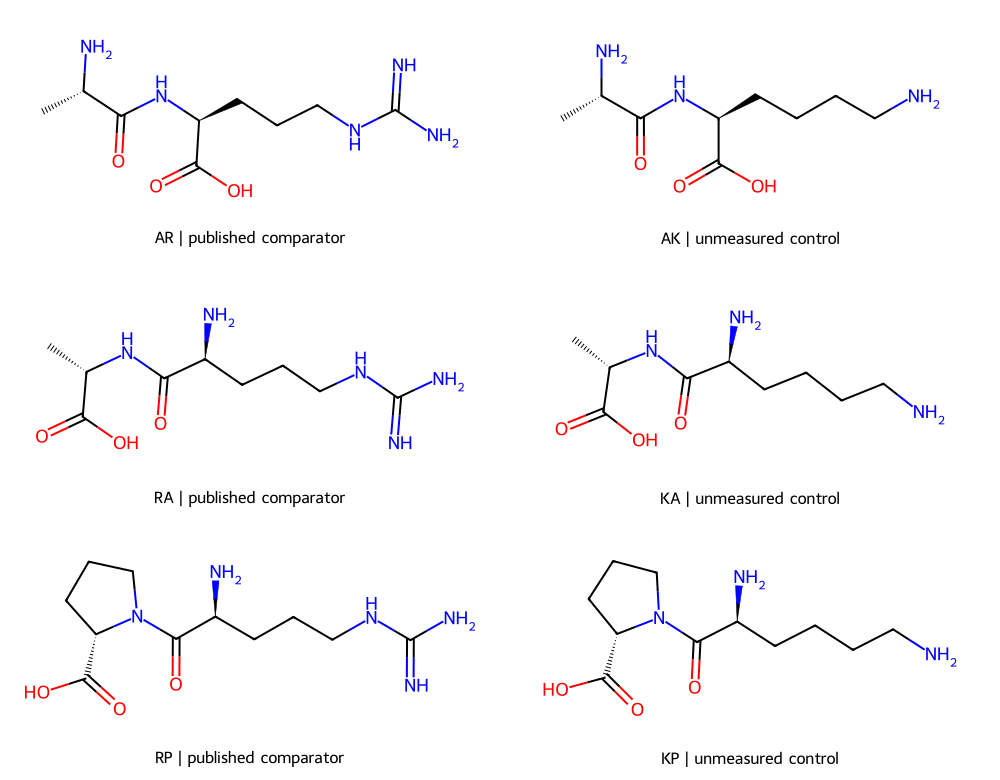

In [4]:
command([PY,EXP/'code/compare_control_panel.py'],'chemical_control_selection')
table(CONTROL/'condition_charge_strata.csv',['peptide_uM','reported_NaCl_stimulus_mM','positive_balance_tested','positive_balance_with_reported_increase','nonpositive_balance_tested','nonpositive_balance_with_reported_increase'])
table(CONTROL/'matched_control_pairs.csv',['reference','proposed_control','reference_sidechain_balance','control_sidechain_balance','control_HBO_result'])
table(CONTROL/'control_panel_chemistry.csv',['sequence','role','formula','free_form_average_MW_g_mol','nominal_sidechain_balance','calculated_free_form_mg_L_at_50_uM'])
# Draw the exact generated graphs using the worker, without 3-D optimization or docking.
drawing="""from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Draw
import csv
p=Path('runs/control_selection');rows=list(csv.DictReader((p/'control_panel_chemistry.csv').open()))
by={r['sequence']:r for r in rows};order=['AR','AK','RA','KA','RP','KP']
mols=[Chem.MolFromSmiles(by[s]['isomeric_SMILES']) for s in order]
labels=[s+' — '+('published comparator' if s in ['AR','RA','RP'] else 'unmeasured control') for s in order]
# ASCII labels are portable across RDKit font backends.
labels=[s+' | '+('published comparator' if s in ['AR','RA','RP'] else 'unmeasured control') for s in order]
img=Draw.MolsToGridImage(mols,molsPerRow=2,subImgSize=(500,260),legends=labels)
img.save(str(p/'matched_control_structures.png'))
"""
command([PY,'-c',drawing],'draw_control_structures')
display(Image(filename=str(CONTROL/'matched_control_structures.png')))


## 4. Convert a mass or concentration without inventing a taste response

These editable parameters perform **unit calculations only**. The defaults answer the earlier example: 10 μg of a compound in 1 mL. Different molecular weights produce different molar exposures at the same mass concentration.

All values assume anhydrous free peptide. An actual counterion, salt form, hydrate or purity correction would change the amount weighed. These are not formulation or tasting instructions, and the calculation does not predict intensity or safety.


In [5]:
MASS_MICROGRAM=10.0
VOLUME_ML=1.0
TARGET_MICROMOLAR=50.0
for label,value in [('mass',MASS_MICROGRAM),('volume',VOLUME_ML),('target concentration',TARGET_MICROMOLAR)]:
    if not isinstance(value,(int,float)) or not math.isfinite(value) or value<=0:raise ValueError(label+' must be finite and positive')
with (CONTROL/'control_panel_chemistry.csv').open() as f:chemistry={r['sequence']:r for r in csv.DictReader(f)}
rows=[]
for sequence in ['AR','AK','RA','KA','RP','KP']:
    mw=float(chemistry[sequence]['free_form_average_MW_g_mol'])
    mass_mg_L=MASS_MICROGRAM/VOLUME_ML
    rows.append({'sequence':sequence,'free_form_MW_g_mol':mw,'input_microgram':MASS_MICROGRAM,'input_volume_mL':VOLUME_ML,
                 'resulting_mg_L':mass_mg_L,'resulting_uM':1000*mass_mg_L/mw,
                 'target_uM':TARGET_MICROMOLAR,'mg_L_at_target_uM':TARGET_MICROMOLAR*mw/1000,
                 'activity_or_taste_prediction':'not made'})
with (CONTROL/'dose_unit_calculator.csv').open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=rows[0].keys());writer.writeheader();writer.writerows(rows)
table(CONTROL/'dose_unit_calculator.csv',['sequence','resulting_mg_L','resulting_uM','target_uM','mg_L_at_target_uM','activity_or_taste_prediction'])
print('Equal mass concentration is not equal molar exposure. A concentration is not a predicted taste.')


dose_unit_calculator.csv: 6 rows
Equal mass concentration is not equal molar exposure. A concentration is not a predicted taste.


sequence,resulting_mg_L,resulting_uM,target_uM,mg_L_at_target_uM,activity_or_taste_prediction
AR,10,40.7692,50,12.2641,not made
AK,10,46.0259,50,10.8634,not made
RA,10,40.7692,50,12.2642,not made
KA,10,46.0259,50,10.8635,not made
RP,10,36.8567,50,13.566,not made
KP,10,41.1003,50,12.1653,not made


## 5. Check the scientific outputs against the reviewed release

Eight CSV outputs are compared with the embedded reviewed tables, allowing only numerical rounding. The 12 SDF chemical graphs are compared by identity and stereochemistry. These checks establish reproduction of retained calculations; they are not an independent biological replication.

The earlier sensory dose of 12 mM is quoted by Xu et al. from Schindler et al.; the original sensory methods were not recovered. Its ratio to 50 μM is 240, **not a potency ratio**. That dose bridge remains unresolved.


In [6]:
reference=PROJECT/'reference'
comparisons=[]
def same_value(a,b):
    if a==b:return True
    try:
        x,y=float(a),float(b)
        return math.isfinite(x) and math.isfinite(y) and math.isclose(x,y,rel_tol=1e-11,abs_tol=1e-12)
    except (ValueError,TypeError):return False
for name in ['condition_summary.csv','component_contrasts.csv','separate_SUM_contrasts.csv','soy_endpoint_comparison.csv','amiloride_contrasts.csv','condition_charge_strata.csv','control_panel_chemistry.csv','matched_control_pairs.csv']:
    fresh=(CONTROL if (CONTROL/name).exists() else RESULTS)/name
    with (reference/name).open(newline='') as f:expected_rows=list(csv.reader(f))
    with fresh.open(newline='') as f:actual_rows=list(csv.reader(f))
    if len(expected_rows)!=len(actual_rows):raise AssertionError('Row count: '+name)
    for i,(left,right) in enumerate(zip(expected_rows,actual_rows)):
        if len(left)!=len(right) or not all(same_value(a,b) for a,b in zip(left,right)):raise AssertionError((name,i))
    comparisons.append({'table':name,'data_rows':len(actual_rows)-1,'matches_reviewed_reference':True})
with (CONTROL/'reference_comparison.csv').open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=comparisons[0].keys());writer.writeheader();writer.writerows(comparisons)
structure_check="""from rdkit import Chem
from pathlib import Path
import json
p=Path('.')
def graphs(path):
    out={}
    for m in Chem.SDMolSupplier(str(path),removeHs=False):
        if m is None:raise ValueError('Invalid SDF record')
        name=m.GetProp('_Name')
        if name in out:raise ValueError('Duplicate SDF name')
        out[name]=Chem.MolToSmiles(Chem.RemoveHs(m),isomericSmiles=True)
    return out
actual=graphs(p/'runs/control_selection/control_panel.sdf');expected=graphs(Path('../../reference/control_panel.sdf'))
assert actual==expected and len(actual)==12
(p/'runs/control_selection/structure_identity_check.json').write_text(json.dumps({'matched_structures':len(actual),'stereochemistry_checked':True},indent=2))
"""
command([PY,'-c',structure_check],'check_chemical_graphs')
table(CONTROL/'reference_comparison.csv')
print((CONTROL/'structure_identity_check.json').read_text())
print('All scientific tables reproduced. Newly entered calculator values are independent unit conversions.')


Running: check_chemical_graphs
check_chemical_graphs: 0.22 s
reference_comparison.csv: 8 rows
{
  "matched_structures": 12,
  "stereochemistry_checked": true
}
All scientific tables reproduced. Newly entered calculator values are independent unit conversions.


table,data_rows,matches_reviewed_reference
condition_summary.csv,7,True
component_contrasts.csv,4,True
separate_SUM_contrasts.csv,3,True
soy_endpoint_comparison.csv,3,True
amiloride_contrasts.csv,2,True
condition_charge_strata.csv,4,True
control_panel_chemistry.csv,12,True
matched_control_pairs.csv,3,True


## 6. Read the decision and export the run

The next biological comparison is **AR/AK and RA/KA**, after the AR response can be reproduced with the original peptide-only, NaCl-only and mixture controls. Positive and negative findings need appropriate expression and perturbation controls. A functional result would still need a separate sensory study before it supports the food-level goal.

This notebook produces an auditable comparator set and a reproduced evidence analysis. It does not establish new peptide activity or determine how a new compound tastes. No amount of A100 runtime replaces the missing measurements.

**Primary sources**

- Xu et al. (2017), human taste-cell calcium responses and perturbation controls: [10.1038/s41598-017-07756-x](https://doi.org/10.1038/s41598-017-07756-x). Full text inspected; original experimental findings attributed to its authors.
- Qi et al. (2025), soy sensory/organoid comparison: [10.1021/acs.jafc.4c12256](https://doi.org/10.1021/acs.jafc.4c12256). Publisher abstract and SI description only; unverified organoid conditions remain blank.
- Schindler et al. (2011), arginyl sensory evidence: [10.1021/jf2041593](https://doi.org/10.1021/jf2041593). Abstract/SI inspected; the 12 mM sensory dose remains a secondary attribution from Xu et al.
- Kino et al. (2015), non-arginyl sensory comparators: [10.3136/nskkk.62.274](https://doi.org/10.3136/nskkk.62.274). Full primary article inspected.
- Stähler et al. (2008), human ENaC and sensory context: [10.1007/s12078-008-9006-4](https://doi.org/10.1007/s12078-008-9006-4). Publisher abstract inspected.
- Bigiani and Rhyu (2023; online 2022), rat γ-glutamyl electrophysiology: [10.1016/j.bbrep.2022.101400](https://doi.org/10.1016/j.bbrep.2022.101400). Full paper inspected; raw data not reanalysed here.

The source manifests and reports in the export give attribution and access limits. The retained SaltyMeta-derived input preserves Chen et al.'s CC BY-SA 4.0 attribution. No full publisher articles are bundled.


In [7]:
summary={
    'CPU_only':True,'GPU_required':False,'embedded_package_sha256':PAYLOAD_SHA256,
    'worker_environment':actual,'reviewed_CSV_tables_reproduced':len(comparisons),
    'chemical_graphs_verified':12,'published_condition_records':functional_summary['condition_records'],
    'new_biological_activity_measured':False,'taste_prediction_for_controls_made':False,
    'elapsed_notebook_seconds':time.monotonic()-NOTEBOOK_STARTED,
    'execution_scope':'Local or Colab Python cells; browser execution is not inferred from this worker receipt.'}
# The variable actual above is the environment dictionary; CSV comparison uses actual_rows.
(PROJECT/'NOTEBOOK_RUN_SUMMARY.json').write_text(json.dumps(summary,indent=2)+'\n')
EXPORT=BASE/'Arginyl_Functional_Controls_Run.zip'
with zipfile.ZipFile(EXPORT,'w',zipfile.ZIP_DEFLATED) as archive:
    for folder in [PROJECT,LOGS]:
        for p in sorted(folder.rglob('*')):
            if p.is_file() and '__pycache__' not in p.parts:
                archive.write(p,p.relative_to(BASE).as_posix())
with zipfile.ZipFile(EXPORT) as archive:
    if archive.testzip() is not None:raise RuntimeError('Export ZIP corruption')
print(json.dumps({k:v for k,v in summary.items() if k!='worker_environment'},indent=2))
print('Export:',EXPORT,'| bytes:',EXPORT.stat().st_size)
display(FileLink(str(EXPORT)))
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(str(EXPORT))


{
  "CPU_only": true,
  "GPU_required": false,
  "embedded_package_sha256": "a72dbc8763f1cd0aa0575a912eefbc369f8f96ac2834bd8fbc4bd45878ab916a",
  "reviewed_CSV_tables_reproduced": 8,
  "chemical_graphs_verified": 12,
  "published_condition_records": 32,
  "new_biological_activity_measured": false,
  "taste_prediction_for_controls_made": false,
  "elapsed_notebook_seconds": 27.456682611999895,
  "execution_scope": "Local or Colab Python cells; browser execution is not inferred from this worker receipt."
}
Export: /workspace/scratch/cadb742a5030/research/arginyl_notebook_20261015/notebook_validation_no_uv/salt_functional_controls/Arginyl_Functional_Controls_Run.zip | bytes: 350150


/workspace/scratch/cadb742a5030/research/arginyl_notebook_20261015/notebook_validation_no_uv/salt_functional_controls/Arginyl_Functional_Controls_Run.zip